# 03 — Perfiles descriptivos y segmentación de SKU

A partir de 174 columnas semanales indexadas, el cuaderno calcula métricas por SKU —demanda media, variabilidad, tendencia, intervalo promedio de demanda (ADI), variabilidad de los periodos no nulos y fracción de semanas con campaña— y compara tres algoritmos de clustering mediante silhouette. La tipología de Syntetos–Boylan complementa el análisis de demanda intermitente; no es una clasificación financiera ni una etiqueta de repuesto u obsolescencia.

La salida registrada selecciona **KMeans, k=5, silhouette=0.4243** y asigna grupos para exploración. La métrica compara particiones en las características elegidas; no acredita segmentos naturales, causalidad ni rentabilidad. Los nombres de segmento son descriptores operativos, deben validarse con Compras y no autorizan por sí solos compras, bajas o liquidaciones.

Los resultados visibles son artefactos previamente ejecutados. El pipeline vuelve a entrenar y sobrescribe Parquet/CSV; abrir y ejecutar este cuaderno fuera de una corrida controlada puede reemplazar salidas que consumen los cuadernos posteriores.

In [1]:
import os
import glob
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

if not os.environ.get("JAVA_HOME"):
    cand = (glob.glob(r"C:\Program Files\Microsoft\jdk-17*")
            + glob.glob(r"C:\Program Files\Eclipse Adoptium\jdk-17*")
            + glob.glob(os.path.expanduser(r"~\AppData\Local\Microsoft\jdk-17*")))
    if cand:
        os.environ["JAVA_HOME"] = cand[0]
        os.environ["PATH"] = os.path.join(cand[0], "bin") + os.pathsep + os.environ.get("PATH", "")

ROOT = "." if os.path.isdir("hadoop") else ".."
_hh = os.path.abspath(os.path.join(ROOT, "hadoop"))
if os.path.isdir(os.path.join(_hh, "bin")):
    os.environ["HADOOP_HOME"] = _hh
    os.environ["PATH"] = os.path.join(_hh, "bin") + os.pathsep + os.environ.get("PATH", "")

spark = (
    SparkSession.builder
    .appName("Starbucks-Segmentacion-Avanzada")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "3g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
PARQUET_DIR = os.path.join(ROOT, "data", "parquet")
print("Spark", spark.version, "| Parquet en:", PARQUET_DIR)

Spark 4.1.2 | Parquet en: ..\data\parquet


## 1. Ingeniería de características por SKU (174 semanas)

Calculamos todas las métricas con agregaciones nativas de Spark (sin UDFs).
La pendiente de tendencia se obtiene con la fórmula cerrada de mínimos cuadrados
$\text{slope} = \dfrac{n\sum xy - \sum x \sum y}{n\sum x^2 - (\sum x)^2}$.


In [2]:
dl = spark.read.parquet(os.path.join(PARQUET_DIR, "demanda_larga"))

agg = (dl.groupBy("SKU").agg(
    F.count("*").alias("n"),
    F.avg("demanda").alias("mean_d"),
    F.stddev("demanda").alias("std_d"),
    F.sum("semana").alias("sx"),
    F.sum(F.col("semana") * F.col("semana")).alias("sxx"),
    F.sum("demanda").alias("sy"),
    F.sum(F.col("semana") * F.col("demanda")).alias("sxy"),
    F.sum(F.when(F.col("demanda") > 0, 1).otherwise(0)).alias("n_nz"),
    F.avg(F.when(F.col("demanda") > 0, F.col("demanda"))).alias("mean_nz"),
    F.stddev(F.when(F.col("demanda") > 0, F.col("demanda"))).alias("std_nz"),
    F.avg(F.col("es_campana").cast("double")).alias("frac_campana"),
))

feat = (agg
    .withColumn("cv", F.when(F.col("mean_d") > 0, F.col("std_d") / F.col("mean_d")).otherwise(0.0))
    .withColumn("slope", F.when(
        (F.col("n") * F.col("sxx") - F.col("sx") * F.col("sx")) != 0,
        (F.col("n") * F.col("sxy") - F.col("sx") * F.col("sy")) /
        (F.col("n") * F.col("sxx") - F.col("sx") * F.col("sx"))).otherwise(0.0))
    .withColumn("ADI", F.when(F.col("n_nz") > 0, F.col("n") / F.col("n_nz")).otherwise(F.col("n").cast("double")))
    .withColumn("cv2_nz", F.when(F.col("mean_nz") > 0,
        F.pow(F.col("std_nz") / F.col("mean_nz"), F.lit(2.0))).otherwise(0.0))
    .fillna({"cv": 0.0, "cv2_nz": 0.0, "slope": 0.0, "frac_campana": 0.0})
)

inf = (spark.read.parquet(os.path.join(PARQUET_DIR, "inf"))
       .select("SKU", "COSTO_UNITARIO", "VIDA_UTIL", "CS_POR_PALLET")
       .withColumn("SKU", F.col("SKU").cast("string"))
       .dropDuplicates(["SKU"]))

feat = (feat.withColumn("SKU", F.col("SKU").cast("string"))
        .join(inf, "SKU", "left")
        .fillna({"COSTO_UNITARIO": 0.0, "VIDA_UTIL": 0.0, "CS_POR_PALLET": 0.0}))
print("SKUs con perfil:", feat.count())
feat.select("SKU", "mean_d", "cv", "slope", "ADI", "cv2_nz", "frac_campana").show(8, truncate=False)


SKUs con perfil: 436


+--------+--------------------+------------------+----------------------+-----------------+------------------+------------+
|SKU     |mean_d              |cv                |slope                 |ADI              |cv2_nz            |frac_campana|
+--------+--------------------+------------------+----------------------+-----------------+------------------+------------+
|100396  |0.0                 |0.0               |0.0                   |174.0            |0.0               |0.0         |
|10535   |0.0                 |0.0               |0.0                   |174.0            |0.0               |0.0         |
|11010882|1.4367816091954022  |1.8922925631383407|0.0031982687434152454 |2.175            |1.1105215189873414|0.0         |
|11014856|0.0                 |0.0               |0.0                   |174.0            |0.0               |0.0         |
|11024033|0.0                 |0.0               |0.0                   |174.0            |0.0               |0.0         |
|1103013

## 2. Tipología de demanda (Syntetos–Boylan)

| | CV² ≤ 0.49 | CV² > 0.49 |
|---|---|---|
| **ADI < 1.32** | Smooth (suave) | Erratic (errática) |
| **ADI ≥ 1.32** | Intermittent (intermitente) | Lumpy (a tirones) |

In [3]:
feat = feat.withColumn("tipologia",
    F.when((F.col("ADI") < 1.32) & (F.col("cv2_nz") <= 0.49), "Smooth")
     .when((F.col("ADI") < 1.32) & (F.col("cv2_nz") > 0.49), "Erratic")
     .when((F.col("ADI") >= 1.32) & (F.col("cv2_nz") <= 0.49), "Intermittent")
     .otherwise("Lumpy"))

(feat.groupBy("tipologia")
     .agg(F.count("*").alias("n_skus"),
          F.round(F.avg("mean_d"), 2).alias("demanda_media"),
          F.round(F.avg("ADI"), 2).alias("ADI_medio"),
          F.round(F.avg("cv2_nz"), 2).alias("cv2_medio"))
     .orderBy(F.desc("n_skus")).show(truncate=False))

+------------+------+-------------+---------+---------+
|tipologia   |n_skus|demanda_media|ADI_medio|cv2_medio|
+------------+------+-------------+---------+---------+
|Intermittent|265   |0.97         |66.66    |0.13     |
|Lumpy       |104   |0.62         |14.08    |1.49     |
|Smooth      |54    |20.89        |1.08     |0.2      |
|Erratic     |13    |5.49         |1.13     |0.71     |
+------------+------+-------------+---------+---------+



## 3. Vectorización y escalado

Las variables tienen escalas muy distintas (unidades, costos, ratios) por lo que
estandarizamos con `StandardScaler` antes de agrupar.

In [4]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml import Pipeline

FEATURES = ["mean_d", "cv", "slope", "ADI", "cv2_nz", "frac_campana", "COSTO_UNITARIO", "VIDA_UTIL"]
assembler = VectorAssembler(inputCols=FEATURES, outputCol="raw", handleInvalid="keep")
scaler = StandardScaler(inputCol="raw", outputCol="features", withMean=True, withStd=True)
prep = Pipeline(stages=[assembler, scaler]).fit(feat)
datos = prep.transform(feat).cache()
print("Vector de", len(FEATURES), "caracteristicas listo. Filas:", datos.count())

Vector de 8 caracteristicas listo. Filas: 436


## 4. Comparación de algoritmos y número de clusters

Evaluamos `KMeans`, `BisectingKMeans` y `GaussianMixture` para k=3,4,5 usando el
coeficiente *silhouette* (cuanto más cercano a 1, mejor separación).

In [5]:
from pyspark.ml.clustering import KMeans, BisectingKMeans, GaussianMixture
from pyspark.ml.evaluation import ClusteringEvaluator

evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="cluster", metricName="silhouette")
resultados = []
modelos = {}
for k in [3, 4, 5]:
    for nombre, algo in [
        ("KMeans", KMeans(featuresCol="features", predictionCol="cluster", k=k, seed=42)),
        ("BisectingKMeans", BisectingKMeans(featuresCol="features", predictionCol="cluster", k=k, seed=42)),
        ("GaussianMixture", GaussianMixture(featuresCol="features", predictionCol="cluster", k=k, seed=42)),
    ]:
        m = algo.fit(datos)
        pred = m.transform(datos)
        n_cl = pred.select("cluster").distinct().count()
        if n_cl < 2:
            print(f"{nombre:16s} k={k}  -> colapso a {n_cl} cluster, descartado")
            continue
        sil = evaluator.evaluate(pred)
        resultados.append((nombre, k, round(sil, 4)))
        modelos[(nombre, k)] = m
        print(f"{nombre:16s} k={k}  silhouette={sil:.4f}")

mejor = max(resultados, key=lambda r: r[2])
print("\nMEJOR:", mejor)

KMeans           k=3  silhouette=0.3508


BisectingKMeans  k=3  -> colapso a 1 cluster, descartado


GaussianMixture  k=3  silhouette=0.1011


KMeans           k=4  silhouette=0.4084


BisectingKMeans  k=4  -> colapso a 1 cluster, descartado


GaussianMixture  k=4  silhouette=0.3282


KMeans           k=5  silhouette=0.4243


BisectingKMeans  k=5  -> colapso a 1 cluster, descartado


GaussianMixture  k=5  silhouette=-0.0104

MEJOR: ('KMeans', 5, 0.4243)


## 5. Modelo ganador y perfilado de segmentos

In [6]:
best_model = modelos[(mejor[0], mejor[1])]
seg = best_model.transform(datos)
print(f"Modelo elegido: {mejor[0]} con k={mejor[1]} (silhouette={mejor[2]})")

perfil = (seg.groupBy("cluster").agg(
    F.count("*").alias("n_skus"),
    F.round(F.avg("mean_d"), 2).alias("demanda_media"),
    F.round(F.avg("cv"), 2).alias("cv_medio"),
    F.round(F.avg("slope"), 3).alias("tendencia"),
    F.round(F.avg("ADI"), 2).alias("ADI_medio"),
    F.round(F.avg("frac_campana"), 2).alias("frac_campana"),
    F.round(F.avg("COSTO_UNITARIO"), 2).alias("costo_medio"),
).orderBy("cluster"))
perfil.show(truncate=False)

Modelo elegido: KMeans con k=5 (silhouette=0.4243)


+-------+------+-------------+--------+---------+---------+------------+-----------+
|cluster|n_skus|demanda_media|cv_medio|tendencia|ADI_medio|frac_campana|costo_medio|
+-------+------+-------------+--------+---------+---------+------------+-----------+
|0      |61    |0.0          |0.0     |0.0      |174.0    |0.0         |14.15      |
|1      |303   |1.8          |4.21    |0.005    |26.24    |0.0         |18.15      |
|2      |38    |20.03        |0.85    |0.034    |1.56     |0.0         |6.26       |
|3      |31    |0.42         |6.82    |0.0      |18.36    |0.0         |14.63      |
|4      |3     |66.87        |1.34    |0.491    |3.5      |0.0         |1.1        |
+-------+------+-------------+--------+---------+---------+------------+-----------+



## 6. Etiquetado de negocio de cada segmento

Asignamos un nombre interpretable según la demanda media y la volatilidad de
cada cluster (alta/media/baja rotación).

In [7]:
stats = {r["cluster"]: r["demanda_media"] for r in perfil.collect()}
orden = sorted(stats, key=lambda c: stats[c])                          
nombres = {}
etiquetas = [
    "Sin demanda observada (validar catalogo)",
    "Rotacion muy baja",
    "Rotacion baja",
    "Rotacion media",
    "Rotacion alta",
]
for i, c in enumerate(orden):
    nombres[c] = etiquetas[i] if i < len(etiquetas) else f"Segmento {c}"

mapping = F.create_map([x for c, n in nombres.items() for x in (F.lit(c), F.lit(n))])
seg = seg.withColumn("segmento", mapping[F.col("cluster")])
(seg.groupBy("cluster", "segmento").count().orderBy("cluster").show(truncate=False))

+-------+----------------------------------------+-----+
|cluster|segmento                                |count|
+-------+----------------------------------------+-----+
|0      |Sin demanda observada (validar catalogo)|61   |
|1      |Rotacion baja                           |303  |
|2      |Rotacion media                          |38   |
|3      |Rotacion muy baja                       |31   |
|4      |Rotacion alta                           |3    |
+-------+----------------------------------------+-----+



## 7. Visualización de los segmentos

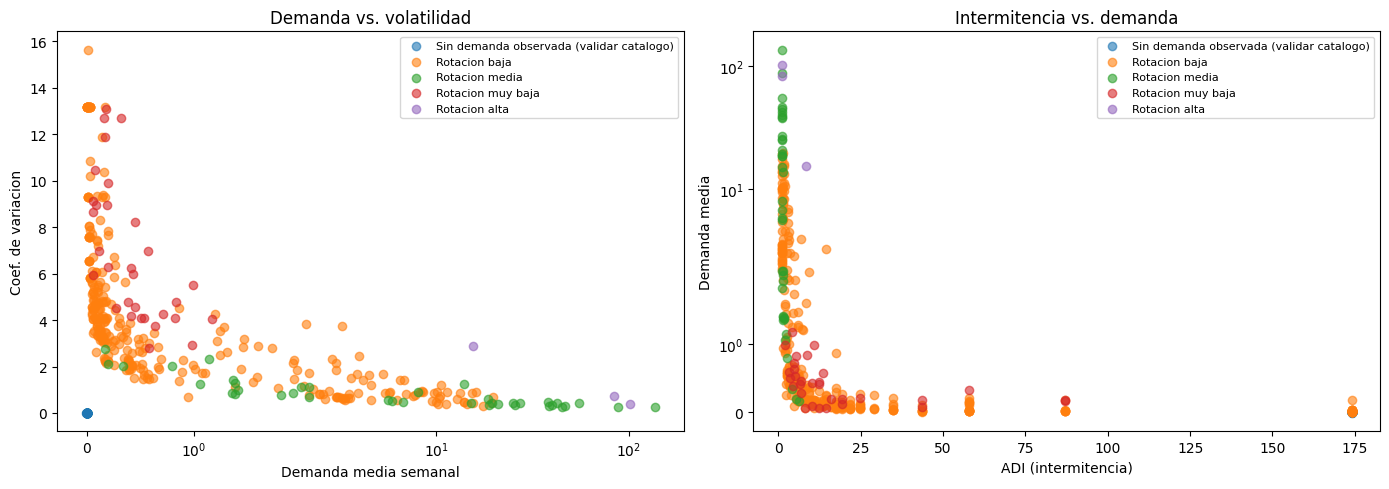

In [8]:
import matplotlib.pyplot as plt

pdf = seg.select("mean_d", "cv", "ADI", "cluster", "segmento").toPandas()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for c in sorted(pdf["cluster"].unique()):
    sub = pdf[pdf["cluster"] == c]
    lbl = sub["segmento"].iloc[0]
    ax[0].scatter(sub["mean_d"], sub["cv"], alpha=0.6, label=lbl)
    ax[1].scatter(sub["ADI"], sub["mean_d"], alpha=0.6, label=lbl)
ax[0].set_xlabel("Demanda media semanal"); ax[0].set_ylabel("Coef. de variacion")
ax[0].set_title("Demanda vs. volatilidad"); ax[0].set_xscale("symlog"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("ADI (intermitencia)"); ax[1].set_ylabel("Demanda media")
ax[1].set_title("Intermitencia vs. demanda"); ax[1].set_yscale("symlog"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Persistencia de los segmentos

In [9]:
salida = seg.select("SKU", "mean_d", "cv", "slope", "ADI", "cv2_nz",
                    "frac_campana", "COSTO_UNITARIO", "VIDA_UTIL",
                    "tipologia", "cluster", "segmento")
salida.write.mode("overwrite").parquet(os.path.join(PARQUET_DIR, "segmentos_sku"))
(salida.coalesce(1).write.mode("overwrite").option("header", True)
       .csv(os.path.join(ROOT, "data", "segmentos_sku_csv")))
print("Segmentos guardados (parquet + CSV).")
spark.stop()
print("SparkSession finalizada.")

Segmentos guardados (parquet + CSV).


SparkSession finalizada.
